# Risk-neutral valuation in SigAlg with binomial trees

The binomial model is the simplest nontrivial model of asset prices, and for that reason it is the standard vehicle for introducing two central ideas of mathematical finance: The absence-of-arbitrage argument that identifies a unique *risk-neutral probability measure* for pricing, and the construction of a *replicating portfolio* that turns a contingent claim's future, uncertain payoff into a definite and computable price today. Despite its simplicity, the binomial model loses none of the conceptual substance of its continuous-time cousins (including the famous Black–Scholes model), and as the number of time steps grows, it converges to them. It is also, happily, a model that SigAlg is well suited to represent exactly, since every binomial tree out to a finite horizon is built from a finite sample space.

This notebook develops risk-neutral valuation for the binomial model from the ground up, using SigAlg throughout to make every step computable. We begin by recalling the general apparatus of discrete-time stochastic processes and filtrations, then specialize to the binomial model itself, introducing the three generation modes (exhaustive enumeration, a sparse representative enumeration, and Monte Carlo simulation) that let the same binomial model scale from a handful of time steps to many. We then turn to *contingent claims*: Path-independent European and American options, the path-dependent Asian option, and a custom-built exotic claim, all expressed in a few lines of SigAlg code. Finally, we develop the theory of risk-neutral pricing itself: The equivalent martingale measure, the self-financing replicating portfolio that justifies it, and, for claims that allow early exercise, the theory of optimal stopping times that extends the pricing formula to American-style options.

This being said, to keep the length of the notebook manageable, the description of the underlying mathematics and the economic motivations for some of the formulas is quite concise. The reader will find it useful to have at hand a textbook that covers this same material at a more leisurely pace, such as Shreve's *Stochastic Calculus for Finance I: The Binomial Asset Pricing Model*. At the bare minimimum, the reader should be familiar with manipulating random variables and their (conditional) expected values.

In [1]:
# If running in Google Colab, uncomment the line below and run this cell first.
# Also, for Mac+Chrome users, beware of a known bug with LaTeX rendering in Colab: https://github.com/googlecolab/colabtools/issues/3192

# !pip install sigalg

## The binomial pricing model

### General stochastic processes

SigAlg models price trajectories of assets as *discrete-time stochastic processes*. Such an object is a collection of random variables $S_t$ (indexed over $t\in \{0,1,\ldots,T\}$) on a fixed probability space $(\Omega, \mathcal{F},P)$. For each sample point $\omega\in \Omega$, we have a sequence of real numbers
$$
(S_0(\omega), S_1(\omega),\ldots,S_T(\omega))\in \mathbb{R}^{T+1},
$$
which is understood as a potential price trajectory of the asset. As the sample point $\omega \in \Omega$ varies, we get different price trajectories, and a price trajectory $(s_0,s_1,\ldots,s_T)\in \mathbb{R}^{T+1}$ has a probability of being observed determined by the probability measure:
$$
P(S_0 = s_0, S_1=s_1,\ldots,S_T=s_T).
$$
The object $\mathcal{F}$ is the *$\sigma$-algebra* of the probability space (the namesake of SigAlg) which, in a sense, encodes the "total information" at hand. It is equipped with a *filtration* induced by the stochastic process, which is a sequence of sub-$\sigma$-algebras terminating with $\mathcal{F}$ itself:
$$
\mathcal{F}_0 \subset \mathcal{F}_1 \subset \cdots \subset \mathcal{F}_T = \mathcal{F}.
$$
The $t$-th $\sigma$-algebra in this filtration is the one generated by the stochastic process up to time $t$:
$$
\mathcal{F}_t = \sigma(S_0,S_1,\ldots,S_t).
$$
The reader unfamiliar with measure-theoretic probability theory should understand $\mathcal{F}_t$ as a partition of the sample space (assuming the sample space is finite, which it always is in SigAlg): Two sample points $\omega$ and $\omega'$ are in the same $\mathcal{F}_t$-component of $\Omega$ if and only if their length-$t$ partial trajectories are equal:
$$
(S_0(\omega),S_1(\omega),\ldots,S_t(\omega)) = (S_0(\omega'),S_1(\omega'),\ldots,S_t(\omega')).
$$
We will also deal with *$\mathcal{F}_t$-measurable random variables*. These are just random variables $X$ on $(\Omega, \mathcal{F}, P)$ that are constant on the $\mathcal{F}_t$-components.

### The definition of a binomial model

A *binomial model* is discrete-time stochastic process $S_t$ that models asset prices with particularly simple dynamics. At any given instant of time $t$, the current price $S_t(\omega)$ may either move up by a factor of $u$, or down by a factor of $d$ (we assume $0< d < 1 < u$), so that either $S_{t+1}(\omega) = uS_t(\omega)$ or $S_{t+1}(\omega) = dS_t(\omega)$. We assume the up-move occurs with probability $p_u$, the down-move with probability $p_d=1-p_u$, and that the price moves are independent over time. We also assume that the initial price $S_0$ is deterministic. The range of the random variable $S_t$ is the set
$$
\{S_0 u^{n}d^{t-n} : n=0,1,\ldots,t\},
$$
and the distribution of $S_t$ is given by
$$
P \left( S_t = S_0u^{n}d^{t-n}\right) = \binom{t}{n}p_u^np_d^{t-n},
$$
for each $n=0,1,\ldots,t$. The probability measure $P$ is called the *real-world measure*, to distinguish it from another probability measure that will come later.

In the following code block, we implement a binomial model in SigAlg with the following parameters:

$$
S_0 = 100, \quad u = 1.1, \quad d = 0.9, \quad p_u = 0.7, \quad R = 1.05, \quad T = 3.
$$

The parameter $R$ is the per-period *risk-free gross return*, which we will discuss below.

In [2]:
import sigalg as sa

S_0, u, d, p_u, R, T = 100, 1.1, 0.9, 0.7, 1.05, 3

S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p_u,
    risk_free_gross_return=R,
    mode="enum",
    length=T,
    name="S",
)
print(S)

Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9


Note that the default sample space generated by SigAlg is the set of integers $\Omega=\{0,1,\ldots,7\}$. For each $\omega\in \Omega$, the corresponding row of the printout gives the price trajectory
$$
(S_0(\omega), S_1(\omega), S_2(\omega), S_3(\omega)).
$$
There are exactly $2^T = 2^3 =8$ distinct price trajectories. We may plot them through the `plot_trajectories` method of the model.

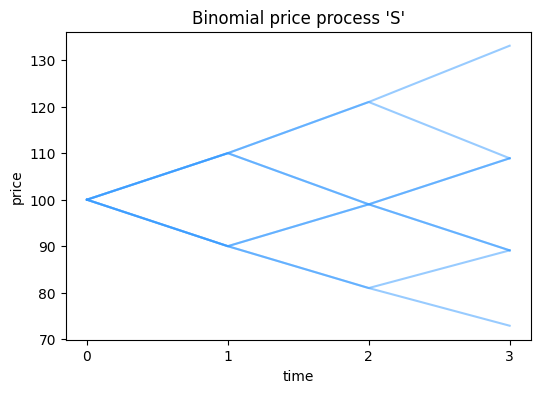

In [3]:
import matplotlib.pyplot as plt

_, ax = plt.subplots(figsize=(6, 4))
S.plot_trajectories(ax=ax, colors=[sa.blue], plot_kwargs={"alpha": 0.5})
plt.show()

The real-world probability measure $P$ is accessible via an appropriate attribute of the model.

In [4]:
P = S.prob_measure
print(P)

Probability measure 'P':
           P
omega       
0      0.343
1      0.147
2      0.147
3      0.063
4      0.147
5      0.063
6      0.063
7      0.027


We may push this measure forward through the random variable $S_3$ to get the probability distribution of the four distinct terminal asset prices. This uses the `>>` operator for pushforwards.

In [5]:
print(P >> S[3])

Probability measure 'P_S_3':
       P_S_3
S_3         
72.9   0.027
89.1   0.189
108.9  0.441
133.1  0.343


Note that these probabilities match the binomial distribution with parameter $p$:

In [6]:
p_d = 1 - p_u
p_d**3, 3 * p_u * p_d**2, 3 * p_u**2 * p_d, p_u**3

(0.027000000000000014, 0.18900000000000003, 0.441, 0.3429999999999999)

### Generation modes

For the binomial model above with $T=3$, there are eight distinct price trajectories, but only four terminal prices. Instead of exhaustively enumerating all $2^T$ price trajectories, sometimes it is convenient to generate a smaller representative collection of $T+1$ trajectories. This may be accomplished by setting the parameter `enum_mode="sparse"` in the call to `generate`.

Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0   90.0   99.0  108.9
2      100.0   90.0   81.0   89.1
3      100.0   90.0   81.0   72.9


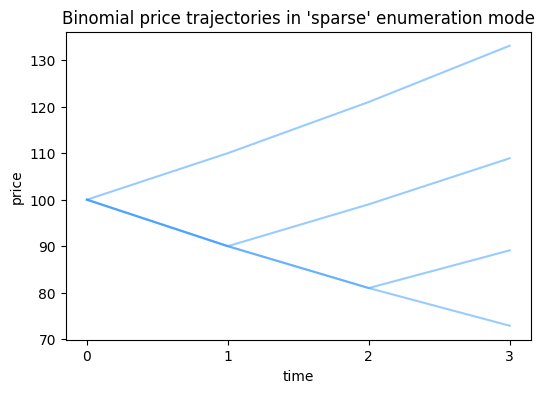

In [7]:
S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p_u,
    risk_free_gross_return=R,
    enum_mode="sparse",
    mode="enum",
    length=T,
    name="S",
)
print(S)

_, ax = plt.subplots(figsize=(6, 4))
S.plot_trajectories(
    ax=ax,
    title="Binomial price trajectories in 'sparse' enumeration mode",
    colors=[sa.blue],
    plot_kwargs={"alpha": 0.5},
)
plt.show()

The representative price trajectories in `sparse` mode are those that do not mix up- and down-moves: All the down-moves are performed first, then all the up-moves.

In addition to sparse enumeration, SigAlg also supports Monte Carlo simulation by setting `mode="sim"`, and specifying the number of trajectories to simulate. We demonstrate this in the next code cell with a new set of parameters and a longer time horizon of $T=100$.

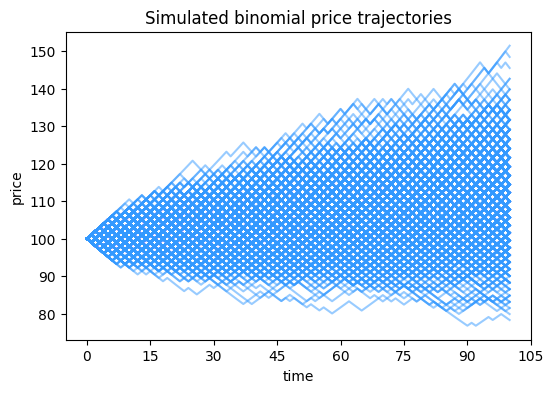

In [8]:
S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=1.01,
    down_factor=0.99,
    up_prob=0.55,
    risk_free_gross_return=1.005,
    mode="sim",
    n_trajectories=1_000,
    length=100,
    name="S",
)

_, ax = plt.subplots(figsize=(6, 4))
S.plot_trajectories(
    ax=ax,
    title="Simulated binomial price trajectories",
    colors=[sa.blue],
    plot_kwargs={"alpha": 0.5},
)
plt.show()

## Contingent claims

### The definition of a contingent claim

Let $S_t$ be the price process of an asset, indexed $t\in \{0,1,\ldots,T\}$ out to some time horizon $T$. A *contingent claim* (or simply a *claim*) is a non-negative stochastic process $\Phi_t$ *adapted* to the filtration $\mathcal{F}_t$ introduced in the previous section. This just means that each $\Phi_t$ is $\mathcal{F}_t$-measurable (for all $t$), which is equivalent to requiring that it is a function of all prices up to (and including) $S_t$:
$$
\Phi_t = \Phi_t(S_0,S_1,\ldots,S_t).
$$
The claim is called *path-independent* if each $\Phi_t$ is $S_t$-measurable (for all $t$), which means that it is a function of the current price alone:
$$
\Phi_t = \Phi_t(S_t).
$$
The time horizon $T$ is called the *maturity time* of the claim. The claim is said to be a *non-early-exercise* claim if $\Phi_t = 0$ for all non-maturity times $t<T$; otherwise, the claim is said to *allow early exercise*.

### European options

One of the simplest examples of a non-early-exercise claim is a *European call option* given by
$$
\Phi_T = \max(S_T-K,0),
$$
where $K$ is a positive real number called the *strike price* of the claim. We may implement this claim in SigAlg by hand using the `from_random_variables` constructor of the `Claim` class. We use a binomial model as the underlying price process $S_t$.

In [9]:
S_0, u, d, p_u, R, T = 100, 1.1, 0.9, 0.7, 1.05, 3

S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p_u,
    risk_free_gross_return=R,
    mode="enum",
    length=T,
    name="S",
)

K = 100
Phi_T = (S[T] - K).max(0)

euro_call = sa.Claim.from_random_variables(
    rvs=[Phi_T], times=[T], model=S, name="euro_call"
)

print("The asset pricing model:")
print(S)

print("\nThe claim payoff at maturity:")
print(Phi_T)

print("\nThe European call option:")
print(euro_call)

The asset pricing model:
Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9

The claim payoff at maturity:
Random variable 'max((S_3 - 100), 0)':
       max((S_3 - 100), 0)
omega                     
0                     33.1
1                      8.9
2                      8.9
3                      0.0
4                      8.9
5                      0.0
6                      0.0
7                      0.0

The European call option:
Claim 'euro_call':
t        0    1    2     3
omega                     
0      0.0  0.0  0.0  33.1
1      0.0  0.0  0.0   8.9
2      0.0  0.0  0.0   8.9
3      0.0  0.0  0.0   0.0
4      0.0  0.0  0.0   8.9
5      0.0  0.0  0.0   0.0
6    

A *European put option* is a non-early-exercise claim with
$$
\Phi_T = \max(K-S_T,0).
$$
It may be implemented in SigAlg by hand just as easily as the call option above; however, SigAlg also includes convenient factory methods for typical contingent claims. The next code block uses one of these methods to construct a European put option in one line.

In [10]:
euro_put = sa.Claim.european_option(strike=K, model=S, type="put", name="euro_put")

print("The asset pricing model:")
print(S)

print("\nThe European put option:")
print(euro_put)

The asset pricing model:
Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9

The European put option:
European option 'euro_put':
t        0    1    2     3
omega                     
0      0.0  0.0  0.0   0.0
1      0.0  0.0  0.0   0.0
2      0.0  0.0  0.0   0.0
3      0.0  0.0  0.0  10.9
4      0.0  0.0  0.0   0.0
5      0.0  0.0  0.0  10.9
6      0.0  0.0  0.0  10.9
7      0.0  0.0  0.0  27.1


### American options

American options are the early-exercise analogues of European options. In particular, an *American call option* with strike $K$ is a claim with

$$
\Phi_t = \max(S_t-K,0)
$$

for all $t$, while an *American put option* with strike $K$ is given by

$$
\Phi_t = \max(K-S_t, 0)
$$

for all $t$. In the first of the next two code blocks, we build an American call option by hand to again illustrate the naturality of the SigAlg API, and then in the second we use a factory method to build an American put option in one line.

In [11]:
Phi = (S - K).max(0)

american_call = sa.Claim.from_stochastic_process(
    process=Phi, model=S, name="american_call"
)

print("The asset pricing model:")
print(S)

print("\nThe American call option:")
print(american_call)

The asset pricing model:
Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9

The American call option:
Claim 'american_call':
t        0     1     2     3
omega                       
0      0.0  10.0  21.0  33.1
1      0.0  10.0  21.0   8.9
2      0.0  10.0   0.0   8.9
3      0.0  10.0   0.0   0.0
4      0.0   0.0   0.0   8.9
5      0.0   0.0   0.0   0.0
6      0.0   0.0   0.0   0.0
7      0.0   0.0   0.0   0.0


In [12]:
american_put = sa.Claim.american_option(
    strike=K, model=S, type="put", name="american_put"
)

print("The asset pricing model:")
print(S)

print("\nThe American put option:")
print(american_put)

The asset pricing model:
Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9

The American put option:
American option 'american_put':
t        0     1     2     3
omega                       
0      0.0   0.0   0.0   0.0
1      0.0   0.0   0.0   0.0
2      0.0   0.0   1.0   0.0
3      0.0   0.0   1.0  10.9
4      0.0  10.0   1.0   0.0
5      0.0  10.0   1.0  10.9
6      0.0  10.0  19.0  10.9
7      0.0  10.0  19.0  27.1


### Asian options

European and American options are path-independent claims. An example of a path-dependent claim is an *Asian call option* with strike $K$, which is given by
$$
\Phi_t = \max(\overline{S}_t- K,0)
$$
for all $t$, where
$$
\overline{S}_t = \frac{1}{1+t} \sum_{k=0}^t S_k
$$
for each $t$. Similarly, an *Asian put option* with strike $K$ is given by
$$
\Phi_t = \max(K-\overline{S}_t,0).
$$
The next pair of code cells follows the pattern above: First constructing an Asian call option by hand, then using a factory method to construct an Asian put option.

In [13]:
Phi = (S.cumavg() - K).max(0)

asian_call = sa.Claim.from_stochastic_process(process=Phi, model=S, name="asian_call")

print("The asset pricing model:")
print(S)

print("\nThe Asian call option:")
print(asian_call)

The asset pricing model:
Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9

The Asian call option:
Claim 'asian_call':
t        0    1          2       3
omega                             
0      0.0  5.0  10.333333  16.025
1      0.0  5.0  10.333333   9.975
2      0.0  5.0   3.000000   4.475
3      0.0  5.0   3.000000   0.000
4      0.0  0.0   0.000000   0.000
5      0.0  0.0   0.000000   0.000
6      0.0  0.0   0.000000   0.000
7      0.0  0.0   0.000000   0.000


In [14]:
asian_put = sa.Claim.asian_option(strike=K, model=S, type="put", name="asian_put")

print("The asset pricing model:")
print(S)

print("\nThe Asian put option:")
print(asian_put)

The asset pricing model:
Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9

The Asian put option:
Asian option 'asian_put':
t        0    1    2       3
omega                       
0      0.0  0.0  0.0   0.000
1      0.0  0.0  0.0   0.000
2      0.0  0.0  0.0   0.000
3      0.0  0.0  0.0   0.475
4      0.0  0.0  0.0   0.525
5      0.0  0.0  0.0   5.475
6      0.0  0.0  0.0   9.975
7      0.0  0.0  0.0  14.025


### Exotic claims

The SigAlg API allows the user to construct claims with all different types of payoff structures. How about a claim that is a mix of an Asian call and a European put, and only allows exercise at two specified times?

In [15]:
Phi_1 = (K - S[1]).max(0)
Phi_3 = (S.cumavg()[3] - K).max(0)

exotic_claim = sa.Claim.from_random_variables(
    rvs=[Phi_1, Phi_3], times=[1, 3], model=S, name="exotic_claim"
)

print("The asset pricing model:")
print(S)

print("\nThe exotic claim:")
print(exotic_claim)

The asset pricing model:
Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9

The exotic claim:
Claim 'exotic_claim':
t        0     1    2       3
omega                        
0      0.0   0.0  0.0  16.025
1      0.0   0.0  0.0   9.975
2      0.0   0.0  0.0   4.475
3      0.0   0.0  0.0   0.000
4      0.0  10.0  0.0   0.000
5      0.0  10.0  0.0   0.000
6      0.0  10.0  0.0   0.000
7      0.0  10.0  0.0   0.000


## Pricing contingent claims

### Equivalent martingale measures (a.k.a., risk-neutral measures)

The unexplained parameter $R$ appearing in the previous few sections is the per-period risk-free gross return, which is used to price contingent claims using binomial models. This is the amount of money resulting from $\$1$ invested at a per-period risk-free rate of $r$, and so $R = 1+r$. We will refer to this risk-free investment as a *bond*, and the risky asset whose price process is a binomial model $S_t$ will be called a *stock*.

The absence of arbitrage opportunities in the two-asset market implies (and is equivalent to) the pair of inequalities
$$
    d < R < u,
$$
where $u$ and $d$ are the up- and down-factors of the binomial model, respectively. Thus, the numbers
$$
q_u \stackrel{\text{def}}{=} \frac{R-d}{u-d}, \qquad q_d \stackrel{\text{def}}{=} 1-q_u = \frac{u-R}{u-d}
$$
are probabilities, called the *risk-neutral probabilities*, and they may be computed using SigAlg.

In [16]:
S_0, u, d, p_u, R, T = 100, 1.1, 0.9, 0.7, 1.05, 3

S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p_u,
    risk_free_gross_return=R,
    mode="enum",
    length=T,
    name="S",
)

q_u, q_d = S.risk_neutral_probs()
print(q_u, q_d)

0.7499999999999999 0.2500000000000001


If $p_u$ and $p_d$ are the real-world probabilities of an upward and downward move of the price, and if $(s_0,s_1,\ldots,s_T)$ is a price trajectory, then we saw that
$$
P(S_0=s_0,S_1=s_1,\ldots,S_T=s_T) = p_u^n p_d^{T-n},
$$
where $n$ is the number of up-moves in the trajectory and $P$ is the real-world measure. If we replace $p_u$ with $q_u$ and $p_d$ with $q_d$, then we get a second measure $Q$ defined by setting
$$
Q(S_0=s_0,S_1=s_1,\ldots,S_T=s_T) = q_u^n q_d^{T-n}.
$$
This latter measure is called the *risk-neutral measure* or *equivalent martingale measure* (*EMM*). SigAlg allows us to compare these two measures.

In [17]:
P = S.prob_measure  # real-world measure
Q = S.emm()  # EMM

print(S)
print(P)
print(Q)

Binomial price process 'S':
t          0      1      2      3
omega                            
0      100.0  110.0  121.0  133.1
1      100.0  110.0  121.0  108.9
2      100.0  110.0   99.0  108.9
3      100.0  110.0   99.0   89.1
4      100.0   90.0   99.0  108.9
5      100.0   90.0   99.0   89.1
6      100.0   90.0   81.0   89.1
7      100.0   90.0   81.0   72.9
Probability measure 'P':
           P
omega       
0      0.343
1      0.147
2      0.147
3      0.063
4      0.147
5      0.063
6      0.063
7      0.027
Probability measure 'Q':
              Q
omega          
0      0.421875
1      0.140625
2      0.140625
3      0.046875
4      0.140625
5      0.046875
6      0.046875
7      0.015625


The "martingale" part of the name *equivalent martingale measure* comes from the fact that the discounted price process is a martingale with respect to $Q$. We recall that this means that
$$
S_t = \frac{1}{R^{r-t}} E_Q(S_r \mid \mathcal{F}_t)
$$
for all $0 \leq t \leq r \leq T$. On the right is an expectation conditioned on a $\sigma$-algebra. The reader unfamiliar with $\sigma$-algebras need not worry; in this special case, this just means that the expectation is conditioned on the random variables $S_0,S_1,\ldots,S_t$.

SigAlg provides both a method to discount the price process $S_t$, as well as a method to check for the martingale property.

In [18]:
S.discount(gross_return=R).is_martingale(prob_measure=Q)

True

### Pricing non-early-exercise claims

One motivation for risk-neutral pricing of contingent claims comes from the theory of replicating portfolios and the absence of arbitrage.

Let $\Phi_t$ be a non-early-exercise contingent claim on a stock with price process $S_t$ with maturity $T$. We suppose that an investor manages a position in both the risk-less bond and the risky stock. Write $B_t$ for the cash position in the bond at time $t$, and $\Delta_t$ for the number of units of stock held at time $t$. We allow $B_t$ and $\Delta_t$ to take on all real values, including negative ones, which represent short positions. The value of the two-asset portfolio at time $t$ is given by the process $V_t$ with
$$
V_t = B_t + S_t \Delta_t.
$$
One time unit later, at time $t+1$, this portfolio will evolve to have value
$$
RB_t + S_{t+1} \Delta_t.
$$
Also at time $t+1$, we imagine that the investor adjusts their positions in the bond and stock, giving a new portfolio value
$$
V_{t+1} = B_{t+1} + S_{t+1} \Delta_{t+1}.
$$
The portfolio is called *self-financing* if the evolved value of the "old" portfolio from time $t$ is equal to the "new" portfolio value at time $t+1$:
$$
V_{t+1} = RB_t + S_{t+1} \Delta_t.
$$
A self-financing portfolio is called a *replicating portfolio* of the non-early-exercise contingent claim $\Phi_t$ if
$$
\Phi_T = RB_{T-1} + S_{T} \Delta_{T-1}.
$$
If we write $X_t$ for the price process of the contingent claim, then in the absence of arbitrage, it is natural to identify $X_t$ with the value process $V_t$ of the replicating portfolio. In particular, the initial price of the claim is $X_0=V_0$, the initial price of the replicating portfolio.

The two processes $B_t$ and $\Delta_t$ should be adapted to the $\mathcal{F}_t$ filtration induced by the price process $S_t$ of the underlying stock. This just means that the values of both $B_t$ and $\Delta_t$ should only depend on the price trajectories of the stock up to time $t$. These properties along with the self-replicating property of the portfolio together imply that the discounted value process of the portfolio is a martingale with respect to the EMM:
$$
V_t = \frac{1}{R^{r-t}} E_Q(V_r \mid \mathcal{F}_t)
$$
for all $0 \leq t \leq r \leq T$. In particular, we have the *risk-neutral pricing formula* for the non-early-exercise contingent claim:
$$
X_0 = \frac{1}{R^T} E_Q(\Phi_T).
$$

SigAlg handles this theory with ease. We use it to compute the replicating portfolio for a simple European call option and identify its risk-neutral price.

In [19]:
K = 100
Phi = sa.Claim.european_option(model=S, strike=K, type="call")

print(Phi)

European option 'Phi':
t        0    1    2     3
omega                     
0      0.0  0.0  0.0  33.1
1      0.0  0.0  0.0   8.9
2      0.0  0.0  0.0   8.9
3      0.0  0.0  0.0   0.0
4      0.0  0.0  0.0   8.9
5      0.0  0.0  0.0   0.0
6      0.0  0.0  0.0   0.0
7      0.0  0.0  0.0   0.0


In [20]:
Delta, B, V = Phi.replicating_portfolio()

print(Delta)
print(B)
print(V)

Stochastic process 'Delta':
t             0         1         2
omega                              
0      0.768707  0.882035  1.000000
1      0.768707  0.882035  1.000000
2      0.768707  0.882035  0.449495
3      0.768707  0.882035  0.449495
4      0.768707  0.353175  0.449495
5      0.768707  0.353175  0.449495
6      0.768707  0.353175 -0.000000
7      0.768707  0.353175 -0.000000
Stochastic process 'B':
t              0          1          2
omega                                 
0     -61.564626 -77.108844 -95.238095
1     -61.564626 -77.108844 -95.238095
2     -61.564626 -77.108844 -38.142857
3     -61.564626 -77.108844 -38.142857
4     -61.564626 -27.244898 -38.142857
5     -61.564626 -27.244898 -38.142857
6     -61.564626 -27.244898   0.000000
7     -61.564626 -27.244898   0.000000
Stochastic process 'V':
t              0          1          2     3
omega                                       
0      15.306122  19.914966  25.761905  33.1
1      15.306122  19.914966  25.761905 

Notice the initial price $V_0 = 15.306122$ of the replicating portfolio. As we mentioned above, this is taken to be the risk-neutral price $X_0$ of the call option. The entire process $X_t$ itself is obtainable through an appropriate method. In the case of a non-early-exercise claim, it coincides with the value process $V_t$.

In [21]:
X = Phi.price_process()

print(X)

Stochastic process 'X':
t              0          1          2     3
omega                                       
0      15.306122  19.914966  25.761905  33.1
1      15.306122  19.914966  25.761905   8.9
2      15.306122  19.914966   6.357143   8.9
3      15.306122  19.914966   6.357143   0.0
4      15.306122   4.540816   6.357143   8.9
5      15.306122   4.540816   6.357143   0.0
6      15.306122   4.540816   0.000000   0.0
7      15.306122   4.540816   0.000000   0.0


If only the price is of interest, not the entire price process, it is obtainable directly from an appropriate method. We check that it is equal to the discounted expectation under the EMM.

In [22]:
import numpy as np

np.allclose(Phi.price(), (1 / R**T) * Phi[T].expectation(measure=Q).item())

True

We also check that the replicating portfolio has the self-financing property.

In [23]:
all(np.allclose(V[t + 1], R * B[t] + S[t + 1] * Delta[t]) for t in range(T))

True

All of these pricing methods also work with the binomial model in `'sparse'` enumeration mode.

In [24]:
S_0, u, d, p_u, R, T = 100, 1.1, 0.9, 0.7, 1.05, 3

S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p_u,
    risk_free_gross_return=R,
    enum_mode="sparse",
    mode="enum",
    length=T,
    name="S",
)

Phi = sa.Claim.european_option(model=S, strike=K, type="call")
Delta, B, V = Phi.replicating_portfolio()

print(Phi)
print(Delta)
print(B)
print(V)

European option 'Phi':
t        0    1    2     3
omega                     
0      0.0  0.0  0.0  33.1
1      0.0  0.0  0.0   8.9
2      0.0  0.0  0.0   0.0
3      0.0  0.0  0.0   0.0
Stochastic process 'Delta':
t             0         1         2
omega                              
0      0.768707  0.882035  1.000000
1      0.768707  0.353175  0.449495
2      0.768707  0.353175  0.000000
3      0.768707  0.353175  0.000000
Stochastic process 'B':
t              0          1          2
omega                                 
0     -61.564626 -77.108844 -95.238095
1     -61.564626 -27.244898 -38.142857
2     -61.564626 -27.244898   0.000000
3     -61.564626 -27.244898   0.000000
Stochastic process 'V':
t              0          1          2     3
omega                                       
0      15.306122  19.914966  25.761905  33.1
1      15.306122   4.540816   6.357143   8.9
2      15.306122   4.540816   0.000000   0.0
3      15.306122   4.540816   0.000000   0.0


The computational efficiency afforded by `'sparse'` enumeration allows us to price claims over many time steps.

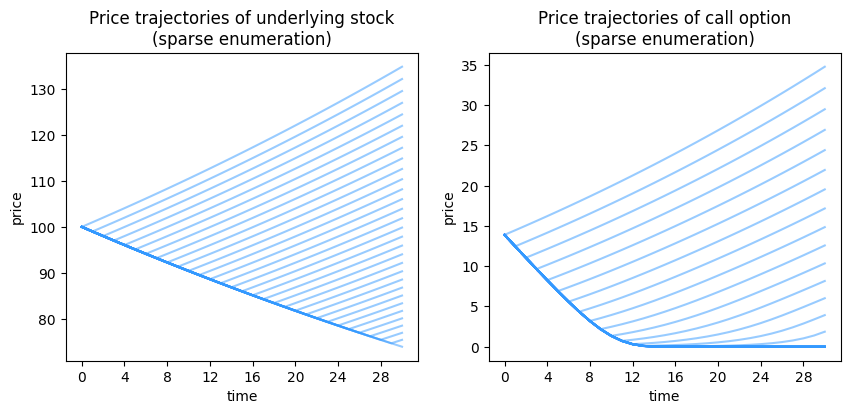

In [25]:
S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=1.01,
    down_factor=0.99,
    up_prob=0.55,
    risk_free_gross_return=1.005,
    enum_mode="sparse",
    mode="enum",
    length=30,
    name="S",
)

Phi = sa.Claim.european_option(model=S, strike=K, type="call")
_, _, V = Phi.replicating_portfolio()

_, axes = plt.subplots(ncols=2, figsize=(10, 4))

S.plot_trajectories(
    ax=axes[0],
    title="Price trajectories of underlying stock\n(sparse enumeration)",
    colors=[sa.blue],
    plot_kwargs={"alpha": 0.5},
)

V.plot_trajectories(
    ax=axes[1],
    y_label="price",
    title="Price trajectories of call option\n(sparse enumeration)",
    colors=[sa.blue],
    plot_kwargs={"alpha": 0.5},
)
plt.show()

### Pricing early-exercise claims

As we saw in the previous section, the price process $X_t$ of a non-early-exercise claim $\Phi_t$ is determined by the one-step martingale formulas
$$
X_t = \frac{1}{R}E_Q(X_{t+1} \mid \mathcal{F}_t), \quad X_T = \Phi_T, \tag{1}
$$
for $0 \leq t < T$. But if $\Phi_t$ allows early exercise, its price process $X_t$ is given instead by
$$
X_t = \max\left(\Phi_t,\ \frac{1}{R}\,E_Q\left(X_{t+1}\mid \mathcal{F}_t\right)\right), \quad X_T = \Phi_T, \tag{2}
$$
for $0 \leq t < T$.

The intuition for the modified formula $(2)$ again comes from the theory of replicating portfolios: The price process $X_t$ gives the least capital needed by the writer of the claim to hedge their short position in the claim. Indeed, at a given time $t$, the writer must be prepared to cover their liabilities in one of two outcomes: Either the claim holder exercises at time $t$ and the writer owes the payoff $\Phi_t$ to the holder, or the holder defers exercise to a future time. In the first case, the writer will require $X_t \geq \Phi_t$ to cover their liability, while in the second case, the writer will require enough capital to purchase a portfolio that replicates the claim's price $X_{t+1}$ at time $t+1$. From the theory in the previous section, we know that this will require
$$
X_t \geq \frac{1}{R}\,E_Q\left(X_{t+1}\mid \mathcal{F}_t\right).
$$
The modified formula (2) then follows.

In this context, the value $\Phi_t$ is called the *intrinsic value* of the claim at time $t$, while the discounted expectation
$$
V_t \stackrel{\text{def}}{=} \frac{1}{R}E_Q(X_{t+1} \mid \mathcal{F}_t)
$$
is called the *continuation value*. Notice that if $\Phi_t$ does not allow early exercise, then $V_t = X_t$ for all $t$ and the definition $(2)$ reduces to the martingale formulas $(1)$ obtained in the previous section for the value process of a replicating portfolio of a non-early-exercise claim. In other words, the two usages of $V_t$, in this section and the previous, do not clash in the situation where they both apply.

An enlightening alternative point of view on this pricing scheme uses the theory of *stopping times*. Intuitively, such an object is a random variable $\tau: \Omega \to \{0,1,\ldots,T,\infty\}$ such that, if $\tau(\omega)=t<\infty$, then the holder of the claim will exercise at time $t$ if they observe the partial price trajectory
$$
(S_0(\omega), S_1(\omega),\ldots,S_t(\omega)).
$$
Their choice to exercise can *only* depend on this partial price trajectory; it cannot depend on any future prices beyond time $t$. In particular, if $\omega'$ is a second sample point whose partial price trajectory
$$
(S_0(\omega'), S_1(\omega'),\ldots,S_t(\omega'))
$$
coincides with the one of $\omega$, then $\tau(\omega') = t$ as well. We allow stopping times to take the value $\infty$, which means that the holder will *never* exercise (i.e., they let the claim expire worthless.)

We may *evaluate* the contingent claim $\Phi_t$ at a stopping time $\tau$, yielding the random variable $\Phi_\tau$ which, evaluated at $\omega$, gives a payoff of $\Phi_{\tau(\omega)}$ to the claim holder at time $\tau(\omega)$. If the holder invested this money in the bond, they would have $R^{T-\tau}\Phi_\tau$ at maturity $T$. This essentially yields a non-early-exercise claim with payoff $R^{T-\tau}\Phi_\tau$ at maturity $T$. From the theory in the previous section, its risk-neutral price is
$$
\frac{1}{R^T} E_Q(R^{T-\tau}\Phi_\tau) = E_Q(R^{-\tau} \Phi_\tau).
$$
But the holder may exercise at *any* stopping time $\tau$, and so the risk-neutral price of the claim should be
$$
X_0 = \max_{\tau} \left(E_Q(R^{-\tau} \Phi_\tau)\right),\tag{3}
$$
where the maximum runs over all stopping times. One of the central theorems in the theory of risk-neutral pricing of early-exercise contingent claims states that the price given in $(3)$ is equal to the one described above in equations (2), and that the optimal stopping time $\tau$ that achieves the maximum is given by
$$
\tau(\omega)= \min \{ t \mid \Phi_t(\omega) \geq V_t(\omega)\},
$$
the first time that the intrinsic value of the claim exceeds its continuation value.

Let's see how all this theory is made concrete using SigAlg. We set up an American put option on a binomial pricing model over $T=8$ time steps.

In [26]:
S_0, u, d, p, R, T = 100, 1.08, 0.9, 0.7, 1.05, 8

S = sa.BinomialPricingModel.generate(
    initial_price=S_0,
    up_factor=u,
    down_factor=d,
    up_prob=p_u,
    risk_free_gross_return=R,
    mode="enum",
    length=T,
    name="S",
)

K = 90
Phi = sa.Claim.american_option(model=S, strike=K, type="put")

We compute the optimal stopping time $\tau$ by calling the `exercise_time` method on the claim.

In [27]:
tau = Phi.exercise_time()

print(tau)

Stopping time 'tau':
       tau
omega     
0      inf
1      inf
2      inf
3      inf
4      inf
...    ...
251    2.0
252    2.0
253    2.0
254    2.0
255    2.0

[256 rows x 1 columns]


We plot the price trajectories of the model, along with dots representing optimal stopping time.

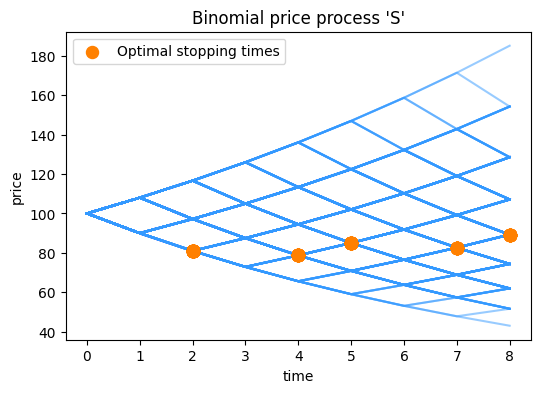

In [28]:
_, ax = plt.subplots(figsize=(6, 4))
S.plot_trajectories(ax=ax, colors=[sa.blue], plot_kwargs={"alpha": 0.5})
ax.scatter(
    tau,
    S.stopped(tau).last_rv,
    color=sa.orange,
    s=75,
    zorder=2,
    label="Optimal stopping times",
)
ax.legend()
plt.show()

Finally, we check that pricing formula
$$
X_0 = E_Q(R^{-\tau} \Phi_\tau)
$$
holds, where $\tau$ is the optimal stopping time.

In [29]:
Q = S.emm()
X = Phi.price_process()
np.allclose(X[0], Phi.discount(gross_return=R).at(tau).expectation(measure=Q))

True